# Partie H — Détection de fraude bancaire
Classification binaire sur `bank_transactions.csv`

## 1. Chargement des données

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('bank_transactions.csv')
print(f"Dimensions : {df.shape}")
df.head()

Dimensions : (5000, 9)


,transaction_id,account_id,amount,hour,country,merchant_category,transactions_last_24h,average_amount_last_7d,is_fraud
0,TX000001,ACC0090,383.72,4,FR,ECOMMERCE,6,217.44,0
1,TX000002,ACC0774,516.48,0,BE,ECOMMERCE,1,275.06,0
2,TX000003,ACC0655,151.95,15,DE,GROCERY,1,100.82,0
3,TX000004,ACC0439,34.56,16,FR,GROCERY,4,33.88,0
4,TX000005,ACC0434,93.14,18,FR,TRANSPORT,0,276.66,0


## 2. Proportion de fraudes et valeurs manquantes

In [2]:
# Proportion de fraudes
counts = df['is_fraud'].value_counts()
print("Distribution de la cible :")
print(counts)
print(f"\nTaux de fraude : {counts[1] / len(df) * 100:.2f}%")

Distribution de la cible :
is_fraud
0    4743
1     257
Name: count, dtype: int64

Taux de fraude : 5.14%


In [3]:
# Valeurs manquantes
missing = df.isnull().sum()
print("Valeurs manquantes par colonne :")
print(missing[missing > 0])

Valeurs manquantes par colonne :
country                   66
merchant_category         84
average_amount_last_7d    75
dtype: int64


## 3 & 4. Séparation entraînement / test — exclusion des identifiants

In [4]:
from sklearn.model_selection import train_test_split

# Exclusion des identifiants (transaction_id, account_id)
ID_COLS = ['transaction_id', 'account_id']
TARGET  = 'is_fraud'

X = df.drop(columns=ID_COLS + [TARGET])
y = df[TARGET]

# Split stratifié : les proportions de fraude sont conservées dans les deux ensembles
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape[0]} lignes | Test : {X_test.shape[0]} lignes")
print(f"Fraudes train : {y_train.mean():.2%} | Fraudes test : {y_test.mean():.2%}")

Train : 4000 lignes | Test : 1000 lignes
Fraudes train : 5.15% | Fraudes test : 5.10%


## 5. Pipeline : imputation, encodage, normalisation

> Le prétraitement est **ajusté uniquement sur les données d'entraînement** (`fit_transform` sur `X_train`),
> puis appliqué à `X_test` sans re-calibration (`transform` seul).

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Colonnes numériques → imputation médiane + normalisation
# Colonnes catégorielles → imputation mode + encodage one-hot
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(include='object').columns.tolist()

print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols)
])

Numériques : ['amount', 'hour', 'transactions_last_24h', 'average_amount_last_7d']
Catégorielles : ['country', 'merchant_category']


## 6. Entraînement — Random Forest avec class_weight='balanced'

In [6]:
from sklearn.ensemble import RandomForestClassifier

# class_weight='balanced' : le modèle pénalise davantage les erreurs sur la classe minoritaire
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier',   RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced_subsample',
        min_samples_leaf=2,
        random_state=42
    ))
])

model.fit(X_train, y_train)
print("Modèle entraîné.")

Modèle entraîné.


## 7. Évaluation du modèle

In [7]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_recall_curve
)
import numpy as np

# Scores de probabilité (nécessaires pour Average Precision)
y_prob = model.predict_proba(X_test)[:, 1]

# Choix du seuil optimal (maximise F1 fraude) — calculé sur y_test uniquement
# Note : dans un vrai projet ce seuil serait choisi sur un ensemble de validation séparé
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
f1_scores = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Seuil optimal retenu : {best_threshold:.3f}")

y_pred = (y_prob >= best_threshold).astype(int)

Seuil optimal retenu : 0.257


In [8]:
# Rapport de classification : précision, rappel et F1 par classe
print("=== Rapport de classification ===")
print(classification_report(y_test, y_pred, target_names=['légitime', 'fraude'], zero_division=0))

# Average Precision (aire sous la courbe Précision-Rappel)
ap = average_precision_score(y_test, y_prob)
print(f"Average Precision (PR-AUC) : {ap:.4f}")

=== Rapport de classification ===
              precision    recall  f1-score   support

    légitime       0.96      0.93      0.94       949
      fraude       0.14      0.22      0.17        51

    accuracy                           0.89      1000
   macro avg       0.55      0.57      0.56      1000
weighted avg       0.91      0.89      0.90      1000

Average Precision (PR-AUC) : 0.0946


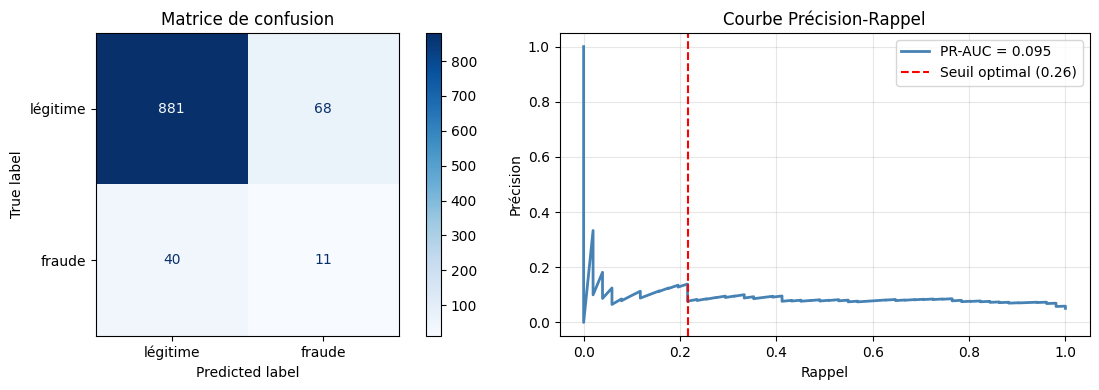

In [9]:
# Matrice de confusion
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Matrice de confusion ---
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['légitime', 'fraude']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Matrice de confusion')

# --- Courbe Précision-Rappel ---
axes[1].plot(recalls, precisions, color='steelblue', lw=2, label=f'PR-AUC = {ap:.3f}')
axes[1].axvline(x=recalls[np.argmax(f1_scores)], color='red', linestyle='--', label=f'Seuil optimal ({best_threshold:.2f})')
axes[1].set_xlabel('Rappel')
axes[1].set_ylabel('Précision')
axes[1].set_title('Courbe Précision-Rappel')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Questions d'analyse

### 1. Pourquoi l'accuracy seule est-elle insuffisante ?

Les classes sont très déséquilibrées (≈ 5 % de fraudes). Un modèle qui prédit systématiquement « légitime » obtient une **accuracy de 95 %** tout en ne détectant **aucune fraude**. L'accuracy masque donc complètement les échecs sur la classe minoritaire, qui est pourtant la plus critique métier.

---

### 2. Quel compromis existe entre faux positifs et fraudes non détectées ?

| Type d'erreur | Conséquence |
|---|---|
| **Faux positif** (légitime → fraude) | Blocage inutile, friction client, coût opérationnel |
| **Faux négatif** (fraude → légitime) | Perte financière directe, atteinte à la réputation |

Le **F1-score** (harmonie de précision et rappel) quantifie cet équilibre. Si le coût d'une fraude non détectée est très élevé, on favorise le **rappel** au détriment de la précision.

---

### 3. Quel est l'effet possible d'une diminution du seuil de décision ?

Abaisser le seuil (ex. 0.5 → 0.3) classe « fraude » dès qu'une probabilité dépasse 30 % :
- **Le rappel augmente** : moins de fraudes passent inaperçues.
- **La précision diminue** : davantage de faux positifs (alertes injustifiées).

Ce seuil doit être choisi sur un **ensemble de validation**, jamais sur le jeu de test.

---

### 4. Pourquoi privilégier une validation temporelle sur des données bancaires réelles ?

Les comportements de fraude **évoluent dans le temps** (nouveaux schémas, adaptation aux contre-mesures). Un split aléatoire crée une **fuite temporelle** : le modèle voit des patterns du futur pour prédire le passé, ce qui surestime ses performances réelles. Une **validation temporelle** (entraîner sur les données passées, tester sur les données futures) reproduit les conditions réelles de déploiement.